# 정상 이미지 기반 병 외관 이상탐지

MVTec AD의 bottle 이미지를 이용해 정상 제품의 특징을 학습하고, 깨짐과 오염을 탐지한다. 이미지 입력부터 OK/NG 판정, 이상 영역 시각화, 검사 기록 저장까지 연결한다.

PaDiM-lite를 중심으로 AutoEncoder와 One-Class SVM의 탐지 성능을 비교하고, 밝기 변화에 따른 정상 이미지의 오탐률을 분석한다.

## 1. 라이브러리 준비

In [13]:
import importlib.util
import os
import subprocess
import sys
import time
from pathlib import Path

try:
    is_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    is_colab = False
if sys.platform != "linux" or not Path("/content").is_dir() or not is_colab:
    raise RuntimeError("Colab 런타임이 필요합니다.")

RUN_START = time.perf_counter()
packages = {"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2,<4",
            "PIL": "Pillow>=10,<13", "scipy": "scipy>=1.11,<2",
            "sklearn": "scikit-learn>=1.4,<2", "matplotlib": "matplotlib>=3.8,<4",
            "ipywidgets": "ipywidgets>=7.7,<9", "joblib": "joblib>=1.3,<2"}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if any(importlib.util.find_spec(module) is None for module in ["torch", "torchvision"]):
    raise RuntimeError("PyTorch가 있는 Colab 런타임을 선택한 뒤 다시 실행하세요.")

import torch
from IPython.display import display
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Remote runtime:", sys.platform, "| Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
ROOT = Path("/content/bottle_inspection")
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

Remote runtime: linux | Device: cuda
GPU: Tesla T4


## 2. 실험 설정

입력 크기는 128×128, AutoEncoder 학습은 20 epoch로 설정한다. 정상 이미지 209장 중 167장은 학습, 42장은 임계값 보정에 사용한다. 테스트는 정상 20장과 불량 63장으로 구성한다.

`alpha=0.05`를 기준으로 정상 보정 점수의 순위에서 임계값을 구한다. **점수가 임계값보다 클 때 NG**로 판정하며, 테스트 전체에 같은 임계값을 적용한다.

In [14]:
CONFIG = {
    "seed": 42, "image_size": 128, "epochs": 20, "batch_size": 32,
    "channels": 48, "grid_size": 16, "alpha": 0.05,
    "score_fraction": 0.01, "padim_sigma": 4.0, "ae_sigma": 2.0,
}
print(CONFIG)

{'seed': 42, 'image_size': 128, 'epochs': 20, 'batch_size': 32, 'channels': 48, 'grid_size': 16, 'alpha': 0.05, 'score_fraction': 0.01, 'padim_sigma': 4.0, 'ae_sigma': 2.0}


## 3. 데이터 수집과 분리

[MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad)의 bottle 카테고리는 정상 학습 이미지, 정상·불량 테스트 이미지, 결함 위치 마스크를 제공한다. 불량 유형은 `broken_large`, `broken_small`, `contamination`이다.

데이터는 [공개 미러](https://huggingface.co/datasets/foersben/mvtec-ad)의 고정 커밋에서 내려받고 파일별 SHA256과 분할 정보를 기록한다. 미러 운영자는 `foersben`이며, 원본 데이터 제공자는 MVTec Software GmbH다. 데이터 라이선스는 **[CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)**이다.

In [15]:
"""MVTec AD bottle 다운로드와 정상 학습/보정/평가 분리."""
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.request import Request, urlopen
from urllib.parse import quote
import hashlib
import json
import re
import time
import numpy as np
from PIL import Image

MIRROR_REPO = "foersben/mvtec-ad"
MIRROR_REVISION = "c75b39616f84db43677bcc8228caaafaf5096d7f"
OFFICIAL_SOURCE = "https://www.mvtec.com/company/research/datasets/mvtec-ad"


def _file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _request_json(url):
    """일시적인 네트워크 오류는 세 번 재시도한다."""
    error = None
    for attempt in range(3):
        try:
            request = Request(url, headers={"User-Agent": "bottle-inspection-practice/1.0"})
            with urlopen(request, timeout=90) as response:
                return json.load(response), response.headers.get("Link", "")
        except Exception as exc:
            error = exc
            time.sleep(1 + attempt * 2)
    raise RuntimeError(f"데이터 목록 요청 실패: {url}") from error


def download_bottle(data_root, revision=MIRROR_REVISION):
    """고정된 공개 미러에서 bottle 원본 PNG와 이용 조건만 내려받는다.

    반환값은 data_root/bottle 경로다. 같은 파일은 검증 후 재사용한다.
    공식 MVTec AD 이용 조건(CC BY-NC-SA 4.0)이 원본 데이터에 적용된다.
    """
    if not re.fullmatch(r"[0-9a-f]{40}", revision):
        raise ValueError("revision은 변경되지 않는 40자리 Git commit SHA여야 합니다.")
    data_root = Path(data_root).expanduser().resolve()
    category_root = data_root / "bottle"
    category_root.mkdir(parents=True, exist_ok=True)
    manifest_path = category_root / "download_manifest.json"
    previous = {}
    if manifest_path.exists():
        prior = json.loads(manifest_path.read_text(encoding="utf-8"))
        if prior.get("revision") == revision:
            previous = {row["path"]: row for row in prior.get("files", [])}

    # API는 페이지가 나뉠 수 있으므로 next 링크가 없어질 때까지 읽는다.
    next_url = (f"https://huggingface.co/api/datasets/{MIRROR_REPO}/tree/"
                f"{revision}/bottle?recursive=true&limit=1000")
    entries = []
    while next_url:
        page, link_header = _request_json(next_url)
        entries.extend(page)
        match = re.search(r'<([^>]+)>;\s*rel="next"', link_header)
        next_url = match.group(1) if match else None

    selected = []
    for entry in entries:
        path = PurePosixPath(entry.get("path", ""))
        if (entry.get("type") == "file" and path.parts
                and path.parts[0] == "bottle" and ".." not in path.parts
                and (path.suffix.lower() == ".png" or path.name in {"license.txt", "readme.txt"})):
            selected.append(entry)
    selected.sort(key=lambda row: row["path"])
    expected_counts = {"train": 209, "test": 83, "ground_truth": 63}
    actual_counts = {
        part: sum(row["path"].startswith(f"bottle/{part}/") and row["path"].endswith(".png")
                  for row in selected)
        for part in expected_counts
    }
    if actual_counts != expected_counts:
        raise RuntimeError(f"bottle 파일 구성이 예상과 다릅니다: {actual_counts}")
    if not {"bottle/license.txt", "bottle/readme.txt"}.issubset({row["path"] for row in selected}):
        raise RuntimeError("원본 데이터 이용 조건 또는 설명 파일이 없습니다.")

    def fetch_one(entry):
        relative = entry["path"]
        target = data_root.joinpath(*PurePosixPath(relative).parts)
        target.parent.mkdir(parents=True, exist_ok=True)
        expected_sha = (entry.get("lfs") or {}).get("oid")
        expected_size = int(entry.get("size", 0))
        prior_sha = previous.get(relative, {}).get("sha256")
        url = f"https://huggingface.co/datasets/{MIRROR_REPO}/resolve/{revision}/{quote(relative)}"
        if target.exists() and target.stat().st_size == expected_size:
            digest = _file_sha256(target)
            trusted_sha = expected_sha or prior_sha
            if trusted_sha and digest == trusted_sha:
                return {"path": relative, "bytes": expected_size, "sha256": digest, "url": url}
        error = None
        part_path = target.with_name(target.name + ".part")
        for attempt in range(3):
            try:
                request = Request(url, headers={"User-Agent": "bottle-inspection-practice/1.0"})
                with urlopen(request, timeout=90) as response, open(part_path, "wb") as output:
                    while True:
                        chunk = response.read(1024 * 1024)
                        if not chunk:
                            break
                        output.write(chunk)
                if part_path.stat().st_size != expected_size:
                    raise ValueError(f"파일 크기 불일치: {relative}")
                digest = _file_sha256(part_path)
                if expected_sha and digest != expected_sha:
                    raise ValueError(f"SHA256 불일치: {relative}")
                if target.suffix.lower() == ".png":
                    with Image.open(part_path) as image:
                        image.verify()
                part_path.replace(target)
                return {"path": relative, "bytes": expected_size, "sha256": digest, "url": url}
            except Exception as exc:
                error = exc
                part_path.unlink(missing_ok=True)
                time.sleep(1 + attempt * 2)
        raise RuntimeError(f"다운로드 실패: {relative}") from error

    records = []
    total_mb = sum(int(row.get("size", 0)) for row in selected) / 1_000_000
    print(f"MVTec AD bottle: {len(selected)}개 파일, 약 {total_mb:.0f} MB")
    with ThreadPoolExecutor(max_workers=4) as pool:
        futures = [pool.submit(fetch_one, entry) for entry in selected]
        for done, future in enumerate(as_completed(futures), start=1):
            records.append(future.result())
            if done % 50 == 0 or done == len(selected):
                print(f"  파일 확인/다운로드 {done}/{len(selected)}")
    manifest = {
        "dataset": "MVTec AD", "category": "bottle",
        "official_source": OFFICIAL_SOURCE,
        "mirror_repo": MIRROR_REPO, "revision": revision,
        "license": "CC BY-NC-SA 4.0", "counts": actual_counts,
        "files": sorted(records, key=lambda row: row["path"]),
    }
    temporary = manifest_path.with_suffix(".json.part")
    temporary.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(manifest_path)
    return category_root


def load_mvtec_arrays(root, img_size=128, seed=42, cal_fraction=0.2):
    """정상 train에서만 train/cal을 분리하고 원래 test는 전부 보존한다.

    반환되는 train/cal/test는 RGB uint8 NHWC, masks_test는 uint8 NHW(0/1).
    y_test는 정상 0, 결함 1이다. test의 라벨/마스크는 평가에만 사용한다.
    """
    root = Path(root).expanduser().resolve()
    if (root / "bottle").is_dir():
        root = root / "bottle"
    if not 0 < cal_fraction < 0.5:
        raise ValueError("cal_fraction은 0보다 크고 0.5보다 작아야 합니다.")
    if img_size < 32:
        raise ValueError("img_size는 32 이상이어야 합니다.")
    normal_paths = sorted((root / "train" / "good").glob("*.png"))
    test_paths = sorted((root / "test").glob("*/*.png"))
    if len(normal_paths) != 209 or len(test_paths) != 83:
        raise ValueError(f"원본 bottle 데이터가 필요합니다. train={len(normal_paths)}, test={len(test_paths)}")
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(normal_paths))
    n_cal = max(1, int(round(len(normal_paths) * cal_fraction)))
    cal_indices = set(order[:n_cal].tolist())
    train_paths = [p for i, p in enumerate(normal_paths) if i not in cal_indices]
    cal_paths = [p for i, p in enumerate(normal_paths) if i in cal_indices]
    splits = {"train": train_paths, "cal": cal_paths, "test": test_paths}

    # 경로와 원본 이미지 해시를 함께 확인해 분할 간 누출을 막는다.
    seen_paths, seen_hashes, manifest_rows = set(), {}, []
    for split, paths in splits.items():
        for path in paths:
            relative = path.relative_to(root).as_posix()
            digest = _file_sha256(path)
            if relative in seen_paths or digest in seen_hashes:
                other = seen_hashes.get(digest, relative)
                raise ValueError(f"중복 이미지/분할 누출: {relative} / {other}")
            seen_paths.add(relative)
            seen_hashes[digest] = relative
            manifest_rows.append({"split": split, "path": relative, "sha256": digest})

    def images(paths):
        rows = []
        for path in paths:
            with Image.open(path) as image:
                rows.append(np.asarray(image.convert("RGB").resize(
                    (img_size, img_size), Image.Resampling.BILINEAR), dtype=np.uint8))
        return np.stack(rows)

    defects = [path.parent.name for path in test_paths]
    y_test = np.array([label != "good" for label in defects], dtype=np.int64)
    masks = []
    for path, defect in zip(test_paths, defects):
        if defect == "good":
            mask = np.zeros((img_size, img_size), dtype=np.uint8)
        else:
            mask_path = root / "ground_truth" / defect / f"{path.stem}_mask.png"
            if not mask_path.is_file():
                raise FileNotFoundError(f"결함 마스크가 없습니다: {mask_path}")
            with Image.open(mask_path) as image:
                mask = (np.asarray(image.convert("L").resize(
                    (img_size, img_size), Image.Resampling.NEAREST)) > 0).astype(np.uint8)
            if not mask.any():
                raise ValueError(f"축소 후 결함 마스크가 비었습니다: {mask_path}")
        masks.append(mask)
    split_manifest = {
        "seed": seed, "cal_fraction": cal_fraction, "image_size": img_size,
        "normal_only_train_cal": True,
        "counts": {name: len(paths) for name, paths in splits.items()},
        "test_normal": int((y_test == 0).sum()),
        "test_anomaly": int(y_test.sum()), "files": manifest_rows,
    }
    return {
        "train": images(train_paths), "cal": images(cal_paths), "test": images(test_paths),
        "y_test": y_test, "masks_test": np.stack(masks),
        "train_paths": [str(p) for p in train_paths],
        "cal_paths": [str(p) for p in cal_paths],
        "test_paths": [str(p) for p in test_paths],
        "defect_types": np.array(defects), "split_manifest": split_manifest,
    }

MVTec AD bottle: 357개 파일, 약 157 MB
  파일 확인/다운로드 50/357
  파일 확인/다운로드 100/357
  파일 확인/다운로드 150/357
  파일 확인/다운로드 200/357
  파일 확인/다운로드 250/357
  파일 확인/다운로드 300/357
  파일 확인/다운로드 350/357
  파일 확인/다운로드 357/357
{'train': 167, 'cal': 42, 'test': 83}
Test normal: 20 | defects: 63


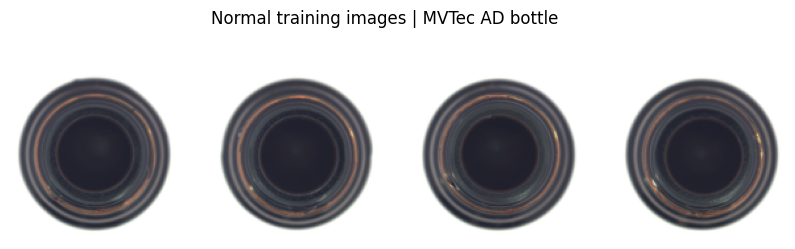

In [16]:
category_root = download_bottle(ROOT / "data")
data = load_mvtec_arrays(category_root, img_size=CONFIG["image_size"], seed=CONFIG["seed"])
import json
(ARTIFACTS / "split_manifest.json").write_text(
    json.dumps(data["split_manifest"], ensure_ascii=False, indent=2), encoding="utf-8")
print(data["split_manifest"]["counts"])
print("Test normal:", int((data["y_test"] == 0).sum()), "| defects:", int(data["y_test"].sum()))
import matplotlib.pyplot as plt
figure, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, image in zip(axes, data["train"][:4]):
    ax.imshow(image)
    ax.axis("off")
figure.suptitle("Normal training images | MVTec AD bottle")
plt.show()

## 4. 모델 구현

| 모델 | 학습 대상 | 이상 점수 | 위치 표시 |
|---|---|---|---|
| PaDiM-lite | ResNet 특징의 위치별 평균·공분산 | Mahalanobis 거리 | 가능 |
| AutoEncoder | 정상 이미지의 복원 패턴 | RGB 재구성 오차 | 가능 |
| OC-SVM | ResNet 전역 특징의 정상 경계 | 음수 decision function | 이미지 단위 판정 |

PaDiM은 사전학습 CNN에서 추출한 정상 특징의 분포를 모델링한다. AutoEncoder는 정상 이미지를 복원하도록 학습한다. OC-SVM은 딥러닝 특징을 입력으로 사용하는 머신러닝 모델이다. 세 모델 모두 점수가 클수록 이상 정도가 높다.

PaDiM-lite는 [PaDiM](https://arxiv.org/abs/2011.08785)을 바탕으로 입력 128×128, 특징 격자 16×16, 선택 채널 48개를 사용한다. PaDiM-lite와 AutoEncoder의 이미지 점수는 이상 맵에서 **상위 1% 픽셀의 평균**으로 계산한다.

In [17]:
"""Normal-only anomaly detection models used by the notebook.

Inputs are RGB uint8 arrays with shape (N, H, W, 3). Scores always increase
with anomaly severity. The caller owns dataset splits and threshold selection.
"""

import math
import random

import numpy as np
import torch
from scipy.ndimage import gaussian_filter
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18


def seed_everything(seed=42):
    """재현 가능한 분할·초기화·배치 순서를 위한 난수 고정."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


def _check_images(images):
    images = np.asarray(images)
    if images.ndim != 4 or images.shape[-1] != 3:
        raise ValueError("Expected RGB images with shape (N, H, W, 3).")
    if images.dtype != np.uint8:
        raise TypeError("Images must be uint8 in [0, 255]; do not normalize twice.")
    return images


def _image_tensor(images):
    return torch.from_numpy(np.array(images, dtype=np.uint8, order="C", copy=True)).permute(0, 3, 1, 2).float() / 255.0


def top_fraction_score(maps, fraction=0.01):
    """전체 픽셀 중 상위 1%의 평균을 이미지 이상 점수로 사용."""
    maps = np.asarray(maps, dtype=np.float32)
    if maps.ndim != 3:
        raise ValueError("Anomaly maps must have shape (N, H, W).")
    if not 0 < fraction <= 1:
        raise ValueError("fraction must be in (0, 1].")
    flat = maps.reshape(len(maps), -1)
    count = max(1, math.ceil(flat.shape[1] * fraction))
    return np.partition(flat, flat.shape[1] - count, axis=1)[:, -count:].mean(axis=1)


def _resize_and_smooth(maps, output_size=128, sigma=4.0):
    size = (output_size, output_size) if isinstance(output_size, int) else tuple(output_size)
    maps = F.interpolate(
        torch.from_numpy(np.ascontiguousarray(maps, dtype=np.float32))[:, None],
        size=size,
        mode="bilinear",
        align_corners=False,
    )[:, 0].numpy()
    if sigma > 0:
        maps = gaussian_filter(maps, sigma=(0, sigma, sigma), mode="reflect")
    return np.asarray(maps, dtype=np.float32)

In [18]:
class FeatureExtractor(nn.Module):
    """Frozen ImageNet ResNet18: multiscale local and global layer3 features.

    We align layer1/2/3 to the layer1 grid, pool to 16 x 16 and select 48 of
    the 448 concatenated channels. The same selected channels are used
    for every image.
    Pretrained-weight download errors are surfaced; random weights are never
    silently substituted.
    """

    def __init__(self, device="cpu", channels=48, grid_size=16, seed=42, pretrained=True):
        super().__init__()
        if not 1 <= channels <= 448:
            raise ValueError("channels must be between 1 and 448.")
        try:
            self.backbone = resnet18(
                weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
            )
        except Exception as error:
            raise RuntimeError(
                "ImageNet ResNet18 weights could not be loaded. Check the Colab "
                "runtime's Internet connection and rerun this cell. For a saved "
                "checkpoint, construct FeatureExtractor(pretrained=False), then "
                "load its full state_dict before extracting features."
            ) from error
        # Layer4/fc are unused; omit them from memory and exported checkpoints.
        self.backbone.layer4 = nn.Identity()
        self.backbone.fc = nn.Identity()
        for parameter in self.backbone.parameters():
            parameter.requires_grad_(False)
        selected = np.random.default_rng(seed).choice(448, channels, replace=False)
        self.register_buffer("selected_indices", torch.as_tensor(selected, dtype=torch.long))
        self.register_buffer("rgb_mean", torch.tensor([0.485, 0.456, 0.406])[None, :, None, None])
        self.register_buffer("rgb_std", torch.tensor([0.229, 0.224, 0.225])[None, :, None, None])
        self.grid_size = int(grid_size)
        self.channels = int(channels)
        self.to(device)
        self.eval()

    def forward(self, images):
        """Accept an NCHW float tensor in [0, 1] on the model's device."""
        x = (images - self.rgb_mean) / self.rgb_std
        x = self.backbone.maxpool(self.backbone.relu(self.backbone.bn1(self.backbone.conv1(x))))
        layer1 = self.backbone.layer1(x)
        layer2 = self.backbone.layer2(layer1)
        layer3 = self.backbone.layer3(layer2)
        aligned = torch.cat([
            layer1,
            F.interpolate(layer2, size=layer1.shape[-2:], mode="nearest"),
            F.interpolate(layer3, size=layer1.shape[-2:], mode="nearest"),
        ], dim=1)
        local = F.adaptive_avg_pool2d(aligned[:, self.selected_indices], self.grid_size)
        global_features = F.adaptive_avg_pool2d(layer3, 1).flatten(1)
        return local, global_features

    def extract(self, images, batch_size=32):
        """Return {'local': N,D,G,G, 'global': N,256} float32 NumPy arrays."""
        images = _check_images(images)
        if batch_size < 1:
            raise ValueError("batch_size must be positive.")
        if len(images) == 0:
            return {
                "local": np.empty((0, self.channels, self.grid_size, self.grid_size), np.float32),
                "global": np.empty((0, 256), np.float32),
            }
        device = self.rgb_mean.device
        local_parts, global_parts = [], []
        self.eval()
        with torch.inference_mode():
            for start in range(0, len(images), batch_size):
                batch = _image_tensor(images[start:start + batch_size]).to(device)
                local, global_features = self(batch)
                local_parts.append(local.cpu().numpy())
                global_parts.append(global_features.cpu().numpy())
        return {
            "local": np.concatenate(local_parts).astype(np.float32, copy=False),
            "global": np.concatenate(global_parts).astype(np.float32, copy=False),
        }


def fit_padim(local_features, ridge=0.01):
    """정상 학습 특징만으로 위치별 평균과 전체 공분산의 역행렬을 계산."""
    features = np.asarray(local_features, dtype=np.float64)
    if features.ndim != 4 or features.shape[0] < 2:
        raise ValueError("PaDiM needs at least two training samples of shape (N,D,H,W).")
    if ridge <= 0:
        raise ValueError("ridge must be positive to regularize covariance matrices.")
    if not np.isfinite(features).all():
        raise ValueError("Features contain a NaN or infinity.")
    n_samples, channels, height, width = features.shape
    # P,N,D: each spatial position has its own multivariate Gaussian.
    per_position = features.reshape(n_samples, channels, -1).transpose(2, 0, 1)
    mean = per_position.mean(axis=1)
    centered = per_position - mean[:, None, :]
    covariance = np.einsum("pnd,pne->pde", centered, centered, optimize=True) / (n_samples - 1)
    covariance += ridge * np.eye(channels, dtype=np.float64)[None]
    precision = np.linalg.inv(covariance)
    return {
        "mean": mean.astype(np.float32),
        "precision": precision.astype(np.float32),
        "grid_shape": (height, width),
        "channels": channels,
        "ridge": float(ridge),
        "n_train": n_samples,
    }


def padim_predict(local_features, state, output_size=128, sigma=4.0, score_fraction=0.01):
    """Return image scores and smoothed Mahalanobis maps, without refitting."""
    features = np.asarray(local_features, dtype=np.float32)
    expected = (state["channels"], *state["grid_shape"])
    if features.ndim != 4 or features.shape[1:] != expected:
        raise ValueError(f"Expected local feature shape (N, {expected}).")
    n_samples = len(features)
    if n_samples == 0:
        size = (output_size, output_size) if isinstance(output_size, int) else tuple(output_size)
        return np.empty(0, np.float32), np.empty((0, *size), np.float32)
    per_image = features.reshape(n_samples, features.shape[1], -1).transpose(0, 2, 1)
    delta = per_image - state["mean"][None]
    squared_distance = np.einsum("npd,pde,npe->np", delta, state["precision"], delta, optimize=True)
    maps = np.sqrt(np.maximum(squared_distance, 0)).reshape(n_samples, *state["grid_shape"])
    maps = _resize_and_smooth(maps, output_size=output_size, sigma=sigma)
    return top_fraction_score(maps, score_fraction), maps

In [19]:
class ConvAutoEncoder(nn.Module):
    """128 -> 8 spatial bottleneck; no skip connections or pretrained weights."""

    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 4, 2, 1), nn.ReLU(inplace=True),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 64, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid(),
        )

    def forward(self, images):
        return self.decoder(self.encoder(images))


def train_autoencoder(images, device="cpu", epochs=20, batch_size=32, lr=1e-3, seed=42):
    """정상 이미지만 MSE로 학습하고 (model, epoch별 history)를 반환."""
    images = _check_images(images)
    if images.shape[1:3] != (128, 128):
        raise ValueError("AutoEncoder expects 128 x 128 images.")
    if len(images) == 0 or epochs < 1 or batch_size < 1:
        raise ValueError("Training data, epochs and batch_size must be nonempty/positive.")
    seed_everything(seed)
    model = ConvAutoEncoder().to(device)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        TensorDataset(_image_tensor(images)),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator,
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for epoch in range(epochs):
        loss_sum = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = F.mse_loss(model(batch), batch)
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach().item() * len(batch)
        epoch_loss = loss_sum / len(images)
        history.append({"epoch": epoch + 1, "train_mse": epoch_loss})
        if epoch == 0 or (epoch + 1) % 5 == 0 or epoch + 1 == epochs:
            print(f"AE {epoch + 1:02d}/{epochs} | normal train MSE {epoch_loss:.6f}")
    model.eval()
    return model, history


def autoencoder_predict(images, model, device=None, batch_size=32, sigma=2.0, score_fraction=0.01):
    """Return image scores and channel-mean squared reconstruction errors."""
    images = _check_images(images)
    if batch_size < 1:
        raise ValueError("batch_size must be positive.")
    device = next(model.parameters()).device if device is None else torch.device(device)
    model.to(device).eval()
    if len(images) == 0:
        return np.empty(0, np.float32), np.empty(images.shape[:3], np.float32)
    maps = []
    with torch.inference_mode():
        for start in range(0, len(images), batch_size):
            batch = _image_tensor(images[start:start + batch_size]).to(device)
            residual = (batch - model(batch)).square().mean(dim=1)
            maps.append(residual.cpu().numpy())
    maps = np.concatenate(maps).astype(np.float32, copy=False)
    if sigma > 0:
        maps = gaussian_filter(maps, sigma=(0, sigma, sigma), mode="reflect")
    return top_fraction_score(maps, score_fraction), maps


def fit_ocsvm(global_features, pca_components=32, nu=0.1, seed=42):
    """Fit scaling, PCA and RBF One-Class SVM on normal training data only.

    PCA is capped at min(requested, n_train - 1, n_features) for small smoke
    inputs. The default setting uses 32 dimensions. nu is an algorithm parameter and
    must not be interpreted as an observed defect rate.
    """
    features = np.asarray(global_features, dtype=np.float32)
    if features.ndim != 2 or len(features) < 2:
        raise ValueError("OC-SVM needs at least two feature vectors of shape (N,D).")
    if pca_components < 1 or not 0 < nu <= 1:
        raise ValueError("pca_components must be positive; nu must be in (0,1].")
    dimensions = min(pca_components, len(features) - 1, features.shape[1])
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=dimensions, svd_solver="full", random_state=seed)),
        ("ocsvm", OneClassSVM(kernel="rbf", gamma="scale", nu=nu)),
    ])
    pipeline.fit(features)
    return pipeline


def ocsvm_predict(global_features, pipeline):
    """Negative decision_function: larger values indicate stronger anomalies."""
    return -pipeline.decision_function(np.asarray(global_features, dtype=np.float32)).astype(np.float32)

## 5. 이상 판정과 검사 기록

평가와 검사 화면에 같은 전처리, 점수 계산, 임계값을 적용한다. 이상 맵은 점수가 높은 위치를 표시하며, 색 범위는 정상 보정 데이터에서 정한다. 픽셀 평가에는 색상 변환 전의 점수를 사용한다.

CNN 가중치, 선택 채널, PaDiM 분포, SVM, 임계값, 실험 설정을 함께 저장한다. 검사 기록에는 입력 이미지, 모델, 점수, 임계값, OK/NG 판정과 처리 시간을 남긴다.

In [20]:
"""평가, 저장 및 검사 화면에서 공통으로 사용하는 시스템 코드."""
import csv
import io
import json
import math
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)


def normal_threshold(scores, alpha=0.05):
    """독립 정상 보정 표본의 보수적 순위 임계값. 판정은 반드시 > 사용."""
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 1 or not len(scores) or not np.isfinite(scores).all():
        raise ValueError("정상 보정 점수를 확인하세요.")
    if not 0 < alpha < 1:
        raise ValueError("alpha는 0과 1 사이여야 합니다.")
    rank = math.ceil((len(scores) + 1) * (1 - alpha))
    if rank > len(scores):
        raise ValueError("이 alpha에 필요한 정상 보정 표본이 부족합니다.")
    return float(np.sort(scores)[rank - 1])


def evaluate_scores(labels, scores, threshold, masks=None, maps=None):
    predictions = np.asarray(scores) > threshold
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    result = {
        "image_auroc": roc_auc_score(labels, scores),
        "image_ap": average_precision_score(labels, scores),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "normal_fpr": fp / (fp + tn), "specificity": tn / (fp + tn),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "threshold": float(threshold),
    }
    result["pixel_auroc"] = (float(roc_auc_score(masks.ravel(), maps.ravel()))
                              if maps is not None else np.nan)
    return result


def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


class BottleInspector:
    """학습 후 단일 입력을 검사하고 같은 판정 기준으로 기록한다."""
    def __init__(self, extractor, padim_state, autoencoder, svm, thresholds,
                 map_limits, model_name="PaDiM-lite", log_path=None, prediction_config=None):
        self.extractor, self.padim_state = extractor, padim_state
        self.autoencoder, self.svm = autoencoder, svm
        self.thresholds, self.map_limits = thresholds, map_limits
        self.model_name = model_name
        self.prediction_config = {"score_fraction": 0.01, "padim_sigma": 4.0, "ae_sigma": 2.0}
        self.prediction_config.update(prediction_config or {})
        self.device = str(next(autoencoder.parameters()).device)
        self.log_path = Path(log_path) if log_path else None
        self.session_id = uuid.uuid4().hex[:12]

    def inspect(self, image, name="image", record=True):
        start = time.perf_counter()
        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image, dtype=np.uint8))
        image = ImageOps.exif_transpose(image).convert("RGB").resize(
            (128, 128), Image.Resampling.BILINEAR)
        array = np.asarray(image, dtype=np.uint8)
        synchronize()
        model_start = time.perf_counter()
        if self.model_name == "AutoEncoder":
            scores, maps = autoencoder_predict(
                array[None], self.autoencoder,
                sigma=self.prediction_config["ae_sigma"],
                score_fraction=self.prediction_config["score_fraction"])
        else:
            features = self.extractor.extract(array[None], batch_size=1)
            if self.model_name == "PaDiM-lite":
                scores, maps = padim_predict(
                    features["local"], self.padim_state,
                    sigma=self.prediction_config["padim_sigma"],
                    score_fraction=self.prediction_config["score_fraction"])
            elif self.model_name == "OC-SVM":
                scores, maps = ocsvm_predict(features["global"], self.svm), None
            else:
                raise ValueError(f"알 수 없는 모델: {self.model_name}")
        synchronize()
        model_ms = (time.perf_counter() - model_start) * 1000
        score, threshold = float(scores[0]), float(self.thresholds[self.model_name])
        result = {"session_id": self.session_id,
                  "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                  "source": str(name), "model": self.model_name,
                  "score": score, "threshold": threshold,
                  "verdict": "NG" if score > threshold else "OK",
                  "model_ms": model_ms,
                  "pipeline_ms": (time.perf_counter() - start) * 1000,
                  "image": array,
                  "map": maps[0] if maps is not None else None}
        if record and self.log_path:
            self.log_path.parent.mkdir(parents=True, exist_ok=True)
            fields = [key for key in result if key not in {"image", "map"}]
            exists = self.log_path.exists() and self.log_path.stat().st_size > 0
            with self.log_path.open("a", newline="", encoding="utf-8") as stream:
                writer = csv.DictWriter(stream, fieldnames=fields)
                if not exists:
                    writer.writeheader()
                writer.writerow({key: result[key] for key in fields})
        return result


def show_inspection(result, map_limits, mask=None):
    """정답 마스크는 평가용 비교 화면에서만 전달한다."""
    has_map = result["map"] is not None
    panels = 3 + int(mask is not None) if has_map else 1
    figure, axes = plt.subplots(1, panels, figsize=(4 * panels, 3.8), squeeze=False)
    axes = axes[0]
    axes[0].imshow(result["image"])
    axes[0].set_title(f"{result['verdict']} | {result['model']}")
    if has_map:
        limit = max(float(map_limits[result["model"]]), 1e-8)
        axes[1].imshow(result["map"], cmap="inferno", vmin=0, vmax=limit)
        axes[1].set_title("Anomaly map (calibration scale)")
        axes[2].imshow(result["image"])
        axes[2].imshow(result["map"], cmap="inferno", alpha=0.5, vmin=0, vmax=limit)
        axes[2].set_title("Location candidate")
        if mask is not None:
            axes[3].imshow(mask, cmap="gray", vmin=0, vmax=1)
            axes[3].set_title("Ground truth (evaluation only)")
    for ax in axes:
        ax.axis("off")
    figure.suptitle(f"score {result['score']:.4f} / threshold {result['threshold']:.4f}"
                   f" | inference {result['model_ms']:.1f} ms")
    figure.tight_layout()
    return figure


def save_inspector(inspector, folder, config):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    torch.save({k: v.detach().cpu() for k, v in inspector.extractor.state_dict().items()},
               folder / "encoder.pt")
    torch.save({k: v.detach().cpu() for k, v in inspector.autoencoder.state_dict().items()},
               folder / "autoencoder.pt")
    np.savez_compressed(folder / "padim.npz", **inspector.padim_state)
    joblib.dump(inspector.svm, folder / "ocsvm.joblib")
    metadata = {"format_version": 1, "config": config,
                "thresholds": inspector.thresholds, "map_limits": inspector.map_limits,
                "primary_model": "PaDiM-lite"}
    (folder / "metadata.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")


def load_inspector(folder, device="cpu", log_path=None):
    """이 노트북에서 생성한 신뢰할 수 있는 체크포인트만 불러온다."""
    folder = Path(folder)
    meta = json.loads((folder / "metadata.json").read_text(encoding="utf-8"))
    config = meta["config"]
    extractor = FeatureExtractor(device=device, channels=config["channels"],
                                 grid_size=config["grid_size"], seed=config["seed"],
                                 pretrained=False)
    extractor.load_state_dict(torch.load(folder / "encoder.pt", map_location=device,
                                        weights_only=True))
    autoencoder = ConvAutoEncoder().to(device)
    autoencoder.load_state_dict(torch.load(folder / "autoencoder.pt", map_location=device,
                                          weights_only=True))
    autoencoder.eval()
    with np.load(folder / "padim.npz", allow_pickle=False) as archive:
        padim_state = {key: archive[key] for key in archive.files}
    padim_state["grid_shape"] = tuple(padim_state["grid_shape"].tolist())
    padim_state["channels"] = int(padim_state["channels"])
    return BottleInspector(extractor, padim_state, autoencoder,
                           joblib.load(folder / "ocsvm.joblib"),
                           meta["thresholds"], meta["map_limits"], log_path=log_path,
                           prediction_config=config)


def make_dashboard(inspector, data):
    """포트 공개 없이 VS Code 노트북 안에서 업로드/샘플/연속 검사를 한다."""
    import ipywidgets as widgets
    from IPython.display import clear_output, display
    selector = widgets.Dropdown(options=[(Path(p).parent.name + "/" + Path(p).name, i)
                                        for i, p in enumerate(data["test_paths"])],
                                description="샘플:")
    model = widgets.Dropdown(options=["PaDiM-lite", "AutoEncoder", "OC-SVM"],
                             value="PaDiM-lite", description="모델:")
    upload = widgets.FileUpload(accept=".png,.jpg,.jpeg", multiple=False,
                                description="이미지 업로드")
    sample_button = widgets.Button(description="선택 이미지 검사", button_style="primary")
    upload_button = widgets.Button(description="업로드 이미지 검사")
    replay_button = widgets.Button(description="순서대로 10장 검사")
    output = widgets.Output()
    status = widgets.HTML("샘플 또는 bottle과 같은 촬영 조건의 이미지를 검사하세요.")
    buttons = [sample_button, upload_button, replay_button]

    def present(result):
        figure = show_inspection(result, inspector.map_limits)
        display(figure)
        plt.close(figure)
        status.value = (f"<b>{result['verdict']}</b> | 점수 {result['score']:.4f} / "
                        f"임계값 {result['threshold']:.4f} | "
                        f"추론 {result['model_ms']:.1f} ms | CSV 저장 완료")

    def action(kind):
        for button in buttons:
            button.disabled = True
        try:
            inspector.model_name = model.value
            with output:
                clear_output(wait=True)
                if kind == "upload":
                    if not upload.value:
                        print("먼저 PNG/JPEG를 선택하세요.")
                        return
                    value = upload.value
                    entry = next(iter(value.values())) if isinstance(value, dict) else value[0]
                    content = bytes(entry["content"])
                    if len(content) > 20 * 1024 * 1024:
                        raise ValueError("20 MB 이하 이미지만 사용하세요.")
                    with Image.open(io.BytesIO(content)) as image:
                        present(inspector.inspect(image, entry.get("name", "upload")))
                elif kind == "sample":
                    index = selector.value
                    present(inspector.inspect(data["test"][index],
                                              Path(data["test_paths"][index]).parent.name + "/" +
                                              Path(data["test_paths"][index]).name))
                else:
                    # 고정 seed로 섞은 테스트 이미지 10장.
                    indices = np.random.default_rng(7).permutation(len(data["test"]))[:10]
                    records = []
                    for index in indices:
                        result = inspector.inspect(data["test"][index],
                                                   Path(data["test_paths"][index]).parent.name + "/" +
                                                   Path(data["test_paths"][index]).name)
                        records.append({k: result[k] for k in ["source", "score", "verdict", "model_ms"]})
                    display(pd.DataFrame(records))
                    present(result)
        except Exception as error:
            with output:
                print(f"검사 실패: {error}")
        finally:
            for button in buttons:
                button.disabled = False

    sample_button.on_click(lambda _: action("sample"))
    upload_button.on_click(lambda _: action("upload"))
    replay_button.on_click(lambda _: action("replay"))
    display(widgets.VBox([widgets.HBox([model, selector]),
                          widgets.HBox([sample_button, replay_button]),
                          widgets.HBox([upload, upload_button]), status, output]))
    return output

## 6. 학습과 성능 평가

정상 학습 이미지 167장으로 스케일러, PCA, SVM, PaDiM 분포와 AutoEncoder를 학습한다. 정상 보정 이미지 42장으로 임계값과 시각화 색 범위를 정하고, 독립 테스트 83장으로 성능을 평가한다.

AUROC와 AP는 이상 점수의 순위를 평가한다. Precision, Recall, F1, 정상 FPR은 보정 임계값에서의 판정 결과를 평가한다. 픽셀 AUROC에는 정상 이미지의 0 마스크를 포함하며 PaDiM-lite와 AutoEncoder에 적용한다. 모델을 저장한 뒤 다시 불러와 같은 입력의 점수와 판정이 유지되는지 확인한다.

In [21]:
# 이 셀은 위에서 정의한 data, CONFIG, DEVICE와 모델/시스템 함수를 사용한다.
import importlib.metadata
import json
import platform
import time

from IPython.display import display

ARTIFACTS.mkdir(parents=True, exist_ok=True)
seed_everything(CONFIG["seed"])
MODEL_NAMES = ["PaDiM-lite", "AutoEncoder", "OC-SVM"]
fit_seconds = {}

# 두 특징 기반 모델은 같은 frozen encoder를 공유한다. 특징 시간은 따로 기록한다.
extractor = FeatureExtractor(
    device=DEVICE,
    channels=CONFIG["channels"],
    grid_size=CONFIG["grid_size"],
    seed=CONFIG["seed"],
)
features = {}
feature_seconds_by_split = {}
for split in ["train", "cal", "test"]:
    synchronize()
    started = time.perf_counter()
    features[split] = extractor.extract(data[split], batch_size=CONFIG["batch_size"])
    synchronize()
    feature_seconds_by_split[split] = time.perf_counter() - started
    print(f"{split}: {len(data[split])}장 특징 추출 {feature_seconds_by_split[split]:.1f}초")
feature_seconds = sum(feature_seconds_by_split.values())

started = time.perf_counter()
padim_state = fit_padim(features["train"]["local"])
fit_seconds["PaDiM-lite"] = time.perf_counter() - started

synchronize()
started = time.perf_counter()
autoencoder, history = train_autoencoder(
    data["train"], device=DEVICE, epochs=CONFIG["epochs"],
    batch_size=CONFIG["batch_size"], seed=CONFIG["seed"], lr=1e-3,
)
synchronize()
fit_seconds["AutoEncoder"] = time.perf_counter() - started

started = time.perf_counter()
svm = fit_ocsvm(features["train"]["global"], pca_components=32, nu=0.1, seed=CONFIG["seed"])
fit_seconds["OC-SVM"] = time.perf_counter() - started

# 정상 cal은 임계값용, test의 정답은 아래 평가에서만 읽는다.
cal_scores, test_scores, cal_maps, test_maps = {}, {}, {}, {}
for split, scores_by_model, maps_by_model in [
    ("cal", cal_scores, cal_maps), ("test", test_scores, test_maps)
]:
    scores_by_model["PaDiM-lite"], maps_by_model["PaDiM-lite"] = padim_predict(
        features[split]["local"], padim_state,
        sigma=CONFIG["padim_sigma"], score_fraction=CONFIG["score_fraction"],
    )
    scores_by_model["AutoEncoder"], maps_by_model["AutoEncoder"] = autoencoder_predict(
        data[split], autoencoder, device=DEVICE, batch_size=CONFIG["batch_size"],
        sigma=CONFIG["ae_sigma"], score_fraction=CONFIG["score_fraction"],
    )
    scores_by_model["OC-SVM"] = ocsvm_predict(features[split]["global"], svm)
    maps_by_model["OC-SVM"] = None

thresholds = {
    name: normal_threshold(cal_scores[name], alpha=CONFIG["alpha"])
    for name in MODEL_NAMES
}
# 색 범위도 test를 보지 않고 정한다. 이 값은 결함 분할 임계값이 아니다.
map_limits = {
    name: max(float(np.quantile(cal_maps[name], 0.999)), 1e-8)
    for name in ["PaDiM-lite", "AutoEncoder"]
}
inspector = BottleInspector(
    extractor, padim_state, autoencoder, svm, thresholds, map_limits,
    model_name="PaDiM-lite", log_path=ARTIFACTS / "inspection_log.csv",
    prediction_config=CONFIG,
)

metrics = pd.DataFrame({
    name: evaluate_scores(
        data["y_test"], test_scores[name], thresholds[name],
        masks=data["masks_test"], maps=test_maps[name],
    )
    for name in MODEL_NAMES
}).T
metrics.index.name = "model"
metrics["fit_seconds"] = pd.Series(fit_seconds)
metrics.to_csv(ARTIFACTS / "metrics.csv", encoding="utf-8-sig")

prediction_rows = []
for name in MODEL_NAMES:
    for index, score in enumerate(test_scores[name]):
        path = Path(data["test_paths"][index])
        prediction = int(float(score) > thresholds[name])
        prediction_rows.append({
            "model": name,
            "path": f"{path.parent.name}/{path.name}",
            "defect_type": str(data["defect_types"][index]),
            "label": int(data["y_test"][index]),
            "score": float(score), "threshold": thresholds[name],
            "prediction": prediction, "verdict": "NG" if prediction else "OK",
        })
predictions = pd.DataFrame(prediction_rows)
predictions.to_csv(ARTIFACTS / "predictions.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(history).to_csv(ARTIFACTS / "history.csv", index=False, encoding="utf-8-sig")

save_inspector(inspector, ARTIFACTS / "models", CONFIG)
restored = load_inspector(ARTIFACTS / "models", device=DEVICE)
# 같은 단일 입력 경로로 저장 전후를 비교한다. 이 검사는 test로 재학습하지 않는다.
roundtrip_checks = {}
for name in MODEL_NAMES:
    inspector.model_name = restored.model_name = name
    original_result = inspector.inspect(data["test"][0], name="roundtrip", record=False)
    restored_result = restored.inspect(data["test"][0], name="roundtrip", record=False)
    np.testing.assert_allclose(
        original_result["score"], restored_result["score"], rtol=1e-5, atol=1e-5,
    )
    assert original_result["verdict"] == restored_result["verdict"]
    if original_result["map"] is not None:
        np.testing.assert_allclose(
            original_result["map"], restored_result["map"], rtol=1e-5, atol=1e-5,
        )
    else:
        assert restored_result["map"] is None
    roundtrip_checks[name] = "passed"
inspector.model_name = restored.model_name = "PaDiM-lite"

versions = {}
for package in ["torch", "torchvision", "numpy", "scipy", "scikit-learn", "pandas",
                "Pillow", "matplotlib", "joblib", "ipywidgets"]:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = None
environment = {
    "python": platform.python_version(), "platform": platform.platform(),
    "device": str(DEVICE), "cuda_available": torch.cuda.is_available(),
    "cuda_device": torch.cuda.get_device_name() if torch.cuda.is_available() else None,
    "versions": versions, "config": CONFIG,
    "feature_seconds": feature_seconds,
    "feature_seconds_by_split": feature_seconds_by_split,
    "fit_seconds_excluding_shared_features": fit_seconds,
    "thresholds": thresholds, "checkpoint_roundtrip": roundtrip_checks,
    "counts": {split: len(data[split]) for split in ["train", "cal", "test"]},
}
(ARTIFACTS / "environment.json").write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8",
)
print(f"공유 특징 추출: {feature_seconds:.1f}초 | 학습 합계: {sum(fit_seconds.values()):.1f}초")
print("저장·복원 일치 검사: 세 모델 통과")
print(f"평가·예측·학습 이력·환경·모델 저장 위치: {ARTIFACTS}")
display(metrics.round(4))

train: 167장 특징 추출 0.2초
cal: 42장 특징 추출 0.0초
test: 83장 특징 추출 0.1초
AE 01/20 | normal train MSE 0.130113
AE 05/20 | normal train MSE 0.050690
AE 10/20 | normal train MSE 0.012704
AE 15/20 | normal train MSE 0.006983
AE 20/20 | normal train MSE 0.004157
공유 특징 추출: 0.3초 | 학습 합계: 1.5초
저장·복원 일치 검사: 세 모델 통과
평가·예측·학습 이력·환경·모델 저장 위치: /content/bottle_inspection/artifacts


,image_auroc,image_ap,precision,recall,f1,normal_fpr,specificity,tn,fp,fn,tp,threshold,pixel_auroc,fit_seconds
model,,,,,,,,,,,,,,
PaDiM-lite,0.9944,0.9983,0.9839,0.9683,0.9760,0.05,0.95,19.0,1.0,2.0,61.0,6.9267,0.9750,0.2436
AutoEncoder,0.7310,0.9171,1.0000,0.4603,0.6304,0.00,1.00,20.0,0.0,34.0,29.0,0.0593,0.6322,1.2857
OC-SVM,0.9667,0.9892,0.9825,0.8889,0.9333,0.05,0.95,19.0,1.0,7.0,56.0,0.2839,NaN,0.0117


## 7. 오탐 및 미탐 사례와 밝기 변화 분석

정상 이미지 중 이상 점수가 높은 2장과 불량 이미지 중 이상 점수가 낮은 2장을 선택해 원본, 이상 맵, 정답 마스크를 비교한다.

정상 테스트 이미지 20장에 밝기 0.7배, 1.0배, 1.3배를 적용하고, 고정된 모델과 임계값으로 오탐률을 비교한다.

처리 시간은 GPU 동기화와 워밍업 후 단일 이미지 20회에서 측정한다. `model_ms`는 특징 추출을 포함한 추론 시간, `pipeline_ms`는 전처리와 추론 시간이다. 파일 읽기, CSV 기록, 화면 표시는 측정에서 제외한다.

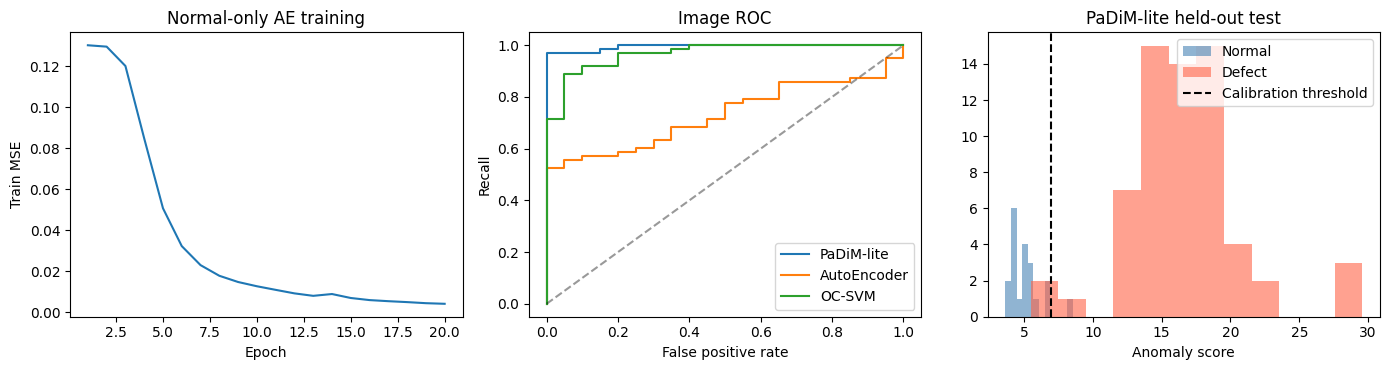

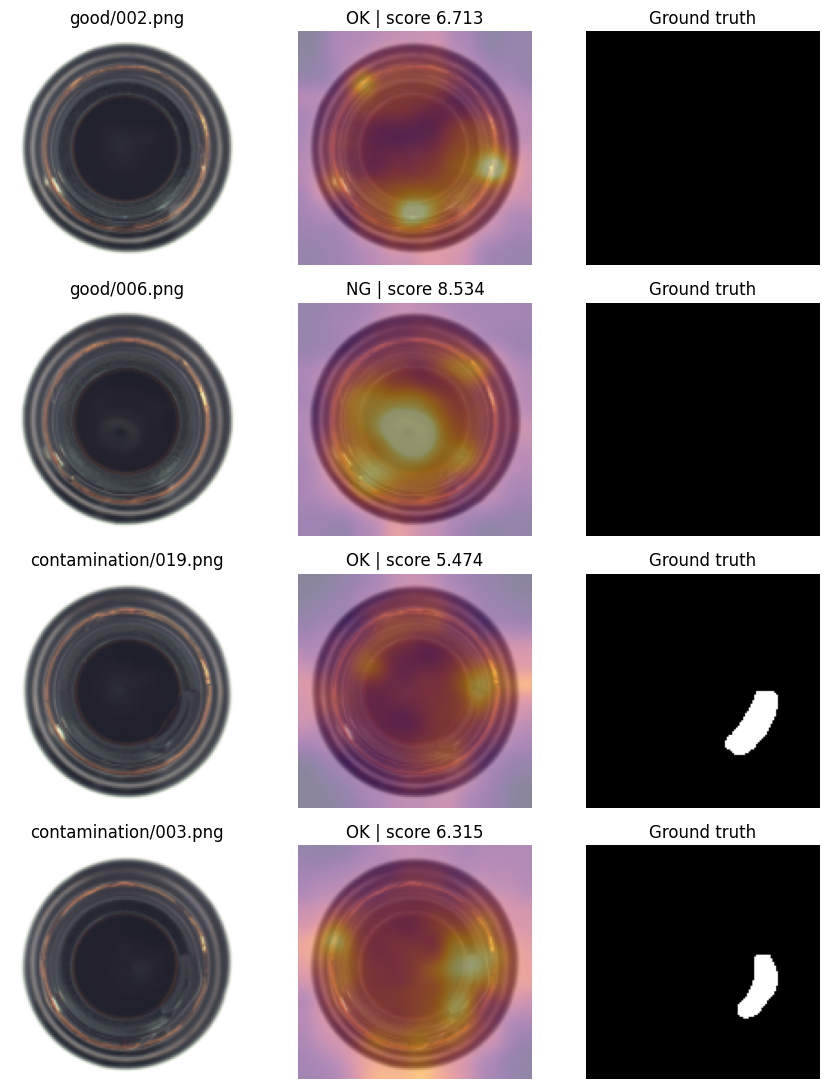

,brightness_factor,model,normal_count,false_alarms,normal_fpr
0,0.7,PaDiM-lite,20,20,1.00
1,0.7,AutoEncoder,20,20,1.00
2,0.7,OC-SVM,20,20,1.00
3,1.0,PaDiM-lite,20,1,0.05
4,1.0,AutoEncoder,20,0,0.00
5,1.0,OC-SVM,20,1,0.05
6,1.3,PaDiM-lite,20,3,0.15
7,1.3,AutoEncoder,20,19,0.95
8,1.3,OC-SVM,20,20,1.00


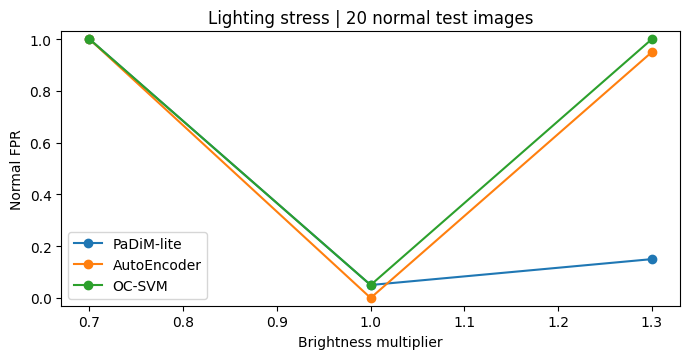

,model,n,inference_p50_ms,inference_p95_ms
0,PaDiM-lite,20,5.925861,6.075219
1,AutoEncoder,20,2.881598,3.136539
2,OC-SVM,20,4.416684,4.550224


,session_id,timestamp_utc,source,model,score,threshold,verdict,model_ms,pipeline_ms
12,9fdf5b7e85d8,2026-10-18T07:33:27.283711+00:00,broken_large/001.png,PaDiM-lite,16.603558,6.926691,NG,6.717937,7.293345
13,9fdf5b7e85d8,2026-10-18T07:33:27.289434+00:00,broken_small/003.png,PaDiM-lite,18.136398,6.926691,NG,5.154208,5.446275
14,9fdf5b7e85d8,2026-10-18T07:33:27.294943+00:00,contamination/007.png,PaDiM-lite,29.569908,6.926691,NG,5.068719,5.271860
15,9fdf5b7e85d8,2026-10-18T07:33:27.300760+00:00,good/010.png,PaDiM-lite,5.280627,6.926691,OK,5.389631,5.633040
16,9fdf5b7e85d8,2026-10-18T07:33:27.306334+00:00,contamination/000.png,PaDiM-lite,15.570182,6.926691,NG,5.112574,5.355214
17,9fdf5b7e85d8,2026-10-18T07:33:27.311778+00:00,broken_large/016.png,PaDiM-lite,15.584860,6.926691,NG,4.938090,5.244284
18,9fdf5b7e85d8,2026-10-18T07:33:27.317225+00:00,broken_small/012.png,PaDiM-lite,18.191843,6.926691,NG,5.057085,5.264591
19,9fdf5b7e85d8,2026-10-18T07:33:27.322527+00:00,broken_small/019.png,PaDiM-lite,13.683289,6.926691,NG,4.837447,5.138087
20,9fdf5b7e85d8,2026-10-18T07:33:27.327882+00:00,broken_large/019.png,PaDiM-lite,15.166435,6.926691,NG,4.931749,5.138900
21,9fdf5b7e85d8,2026-10-18T07:33:27.333405+00:00,broken_small/008.png,PaDiM-lite,12.161402,6.926691,NG,5.127714,5.333033


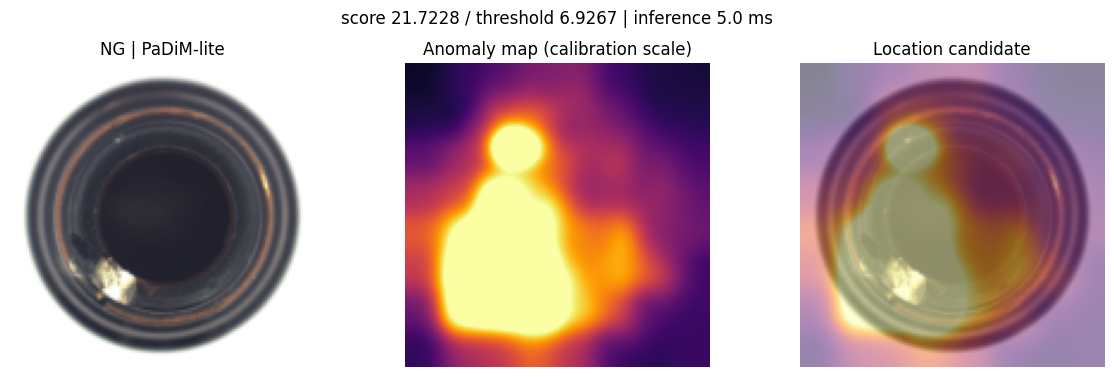

{
  "primary_model": "PaDiM-lite",
  "train_normal": 167,
  "calibration_normal": 42,
  "test_images": 83,
  "image_auroc": 0.9944444444444445,
  "recall": 0.9682539682539683,
  "normal_fpr": 0.05,
  "fn": 2,
  "fp": 1,
  "checkpoint_reload": "passed for all 3 models",
  "elapsed_seconds": 18.2,
  "scope": "bottle-only replay prototype; camera integration not tested"
}


In [22]:
# 모든 그래프는 현재 실행 결과로 생성한다.
figure, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot([row["epoch"] for row in history], [row["train_mse"] for row in history])
axes[0].set(xlabel="Epoch", ylabel="Train MSE", title="Normal-only AE training")
for name in thresholds:
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(data["y_test"], test_scores[name])
    axes[1].plot(fpr, tpr, label=name)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set(xlabel="False positive rate", ylabel="Recall", title="Image ROC")
axes[1].legend()
primary_scores = test_scores["PaDiM-lite"]
for label, color in [(0, "steelblue"), (1, "tomato")]:
    axes[2].hist(primary_scores[data["y_test"] == label], bins=12, alpha=0.6,
                 label="Normal" if label == 0 else "Defect", color=color)
axes[2].axvline(thresholds["PaDiM-lite"], color="black", linestyle="--", label="Calibration threshold")
axes[2].set(xlabel="Anomaly score", title="PaDiM-lite held-out test")
axes[2].legend()
figure.tight_layout()
figure.savefig(ARTIFACTS / "evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

# 정상품 중 점수가 가장 큰 2장과 불량품 중 점수가 가장 작은 2장: 어려운 사례를 고정 규칙으로 선택.
normal_ids = np.where(data["y_test"] == 0)[0]
defect_ids = np.where(data["y_test"] == 1)[0]
hard_ids = np.r_[normal_ids[np.argsort(primary_scores[normal_ids])[-2:]],
                 defect_ids[np.argsort(primary_scores[defect_ids])[:2]]]
figure, axes = plt.subplots(4, 3, figsize=(9, 11))
for row, index in enumerate(hard_ids):
    heatmap = test_maps["PaDiM-lite"][index]
    axes[row, 0].imshow(data["test"][index])
    axes[row, 0].set_title(f"{data['defect_types'][index]}/{Path(data['test_paths'][index]).name}")
    axes[row, 1].imshow(data["test"][index])
    axes[row, 1].imshow(heatmap, cmap="inferno", alpha=0.5, vmin=0,
                        vmax=map_limits["PaDiM-lite"])
    verdict = "NG" if primary_scores[index] > thresholds["PaDiM-lite"] else "OK"
    axes[row, 1].set_title(f"{verdict} | score {primary_scores[index]:.3f}")
    axes[row, 2].imshow(data["masks_test"][index], cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Ground truth")
for ax in axes.flat:
    ax.axis("off")
figure.tight_layout()
figure.savefig(ARTIFACTS / "hard_cases.png", dpi=150, bbox_inches="tight")
plt.show()

# 테스트 라벨은 이 오탐 측정의 정상 subset 선택에만 사용. 임계값/모델은 다시 맞추지 않는다.
brightness_rows = []
normal_test = data["test"][normal_ids]
for factor in [0.7, 1.0, 1.3]:
    changed = np.clip(normal_test.astype(np.float32) * factor, 0, 255).astype(np.uint8)
    changed_features = extractor.extract(changed, batch_size=CONFIG["batch_size"])
    changed_scores = {
        "PaDiM-lite": padim_predict(changed_features["local"], padim_state,
                                    sigma=CONFIG["padim_sigma"],
                                    score_fraction=CONFIG["score_fraction"])[0],
        "AutoEncoder": autoencoder_predict(changed, autoencoder,
                                           sigma=CONFIG["ae_sigma"],
                                           score_fraction=CONFIG["score_fraction"])[0],
        "OC-SVM": ocsvm_predict(changed_features["global"], svm),
    }
    for name, scores in changed_scores.items():
        alarm_count = int((scores > thresholds[name]).sum())
        brightness_rows.append({"brightness_factor": factor, "model": name,
                                "normal_count": len(scores), "false_alarms": alarm_count,
                                "normal_fpr": alarm_count / len(scores)})
brightness = pd.DataFrame(brightness_rows)
brightness.to_csv(ARTIFACTS / "brightness_stress.csv", index=False)
display(brightness)
figure, ax = plt.subplots(figsize=(7, 3.7))
for name, group in brightness.groupby("model", sort=False):
    ax.plot(group["brightness_factor"], group["normal_fpr"], marker="o", label=name)
ax.set(xlabel="Brightness multiplier", ylabel="Normal FPR", ylim=(-0.03, 1.03),
       title=f"Lighting stress | {len(normal_ids)} normal test images")
ax.legend()
figure.tight_layout()
figure.savefig(ARTIFACTS / "brightness_stress.png", dpi=150, bbox_inches="tight")
plt.show()

# 단일 이미지 추론 시간. 파일 읽기/CSV 기록/화면 렌더링은 제외한다.
timing_rows = []
for name in thresholds:
    inspector.model_name = name
    for _ in range(3):
        inspector.inspect(data["test"][0], record=False)
    samples = [inspector.inspect(image, record=False)
               for image in data["test"][:20]]
    milliseconds = [row["model_ms"] for row in samples]
    timing_rows.append({"model": name, "n": len(samples),
                        "inference_p50_ms": float(np.percentile(milliseconds, 50)),
                        "inference_p95_ms": float(np.percentile(milliseconds, 95))})
latency = pd.DataFrame(timing_rows)
latency.to_csv(ARTIFACTS / "latency.csv", index=False)
display(latency)
inspector.model_name = "PaDiM-lite"

# 입력 → 판정 → CSV 기록을 연결해 자동으로 12장 검사한다.
for index in np.random.default_rng(7).permutation(len(data["test"]))[:12]:
    path = Path(data["test_paths"][index])
    result = inspector.inspect(data["test"][index], f"{path.parent.name}/{path.name}")
display(pd.read_csv(ARTIFACTS / "inspection_log.csv").tail(12))
figure = show_inspection(result, inspector.map_limits)
figure.savefig(ARTIFACTS / "inspection_example.png", dpi=150, bbox_inches="tight")
plt.show()

summary = {
    "primary_model": "PaDiM-lite", "train_normal": len(data["train"]),
    "calibration_normal": len(data["cal"]), "test_images": len(data["test"]),
    "image_auroc": float(metrics.loc["PaDiM-lite", "image_auroc"]),
    "recall": float(metrics.loc["PaDiM-lite", "recall"]),
    "normal_fpr": float(metrics.loc["PaDiM-lite", "normal_fpr"]),
    "fn": int(metrics.loc["PaDiM-lite", "fn"]),
    "fp": int(metrics.loc["PaDiM-lite", "fp"]),
    "checkpoint_reload": "passed for all 3 models",
    "elapsed_seconds": round(time.perf_counter() - RUN_START, 1),
    "scope": "bottle-only replay prototype; camera integration not tested",
}
(ARTIFACTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2))

## 8. 이미지 검사

테스트 이미지 83장을 샘플로 사용하며, PNG/JPEG 파일도 입력할 수 있다. 선택한 모델의 OK/NG 판정과 이상 점수를 표시하고, PaDiM-lite와 AutoEncoder는 이상 영역을 함께 표시한다.

연속 검사는 테스트 이미지 10장을 순서대로 처리한다. 검사 결과는 `inspection_log.csv`에 누적 저장한다.

In [23]:
dashboard = make_dashboard(inspector, data)

## 9. 결과 저장

평가 지표, 예측 결과, 학습 이력, 검사 로그와 시각화 이미지를 `inspection_results.zip`에 저장한다. 모델 가중치와 판정 설정은 `inspection_checkpoint.zip`에 저장한다. 데이터 출처와 라이선스도 결과에 포함한다.

In [24]:
import shutil
import zipfile

attribution = """Dataset: MVTec AD, bottle. Copyright MVTec Software GmbH.
Source: https://www.mvtec.com/research-teaching/datasets/mvtec-ad
License for dataset and derived dataset figures: CC BY-NC-SA 4.0
https://creativecommons.org/licenses/by-nc-sa/4.0/
Mirror: foersben/mvtec-ad, revision c75b39616f84db43677bcc8228caaafaf5096d7f
Method: Defard et al., PaDiM, https://arxiv.org/abs/2011.08785
Configuration: 128x128 input, 16x16 feature grid, 48 channels, top-1-percent image scores.
"""
(ARTIFACTS / "DATA_ATTRIBUTION.txt").write_text(attribution, encoding="utf-8")
for filename in ["license.txt", "readme.txt", "download_manifest.json"]:
    shutil.copy2(category_root / filename, ARTIFACTS / ("dataset_" + filename))
with zipfile.ZipFile(ROOT / "inspection_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in ARTIFACTS.rglob("*"):
        if path.is_file() and "models" not in path.relative_to(ARTIFACTS).parts:
            archive.write(path, path.relative_to(ARTIFACTS))
shutil.make_archive(str(ROOT / "inspection_checkpoint"), "zip", ARTIFACTS / "models")
print("결과:", ROOT / "inspection_results.zip")
print("모델:", ROOT / "inspection_checkpoint.zip")


결과: /content/bottle_inspection/inspection_results.zip
모델: /content/bottle_inspection/inspection_checkpoint.zip


## 10. 결과 분석

`metrics.csv`의 Recall과 정상 FPR을 함께 비교하고, `hard_cases.png`에서 결함 위치와 오탐·미탐 여부를 확인한다. 밝기별 FPR은 촬영 조건 변화에 대한 민감도를 보여준다. 정상 테스트가 20장이므로 오탐 1장에 따라 FPR이 5%p씩 달라진다.

AUROC는 이상 점수의 순위를, Recall은 정해진 임계값에서 검출한 불량의 비율을 나타낸다. 두 지표와 밝기 변화 결과를 바탕으로 촬영 조건 및 정상 학습 데이터의 개선 방향을 분석한다.

참고 자료: [MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad), [PaDiM 논문](https://arxiv.org/abs/2011.08785), [PyTorch ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html), [One-Class SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html).